# Esperimento frange di intensità luminosa di interferenza e diffrazione

#### Importiamo le librerie necessarie e definiamo le costanti

In [ ]:
import matplotlib.pyplot as plt
import math
import numpy as np

In [59]:
B = 20
I0=400
alfa = 1.50
delta = 5.20
rng=np.random.default_rng(3297894501)

##### Definiamo le funzioni del modello dividendo la funzione mu in due sottofunzioni e calcoliamo l'inviluppo

In [60]:
x = np.linspace(-5.0, 5.0, 161)

def E(array1):
    return np.sinc(alfa*array1/np.pi)**2

def C(array2):
    return (np.cos(delta*array2))**2

def Mu(array1):
    return B+I0*E(array1)*C(array1)

inviluppo=B+I0*E(x)

##### Controlliamo che il modello si comporti coerentemente con le aspettative fisiche

In [61]:
if np.all(Mu(x)>=0) and np.all(np.isfinite(Mu(x))) and np.all(Mu(x)==Mu(-x)) and Mu(0)==B+I0:
    print(True)

True


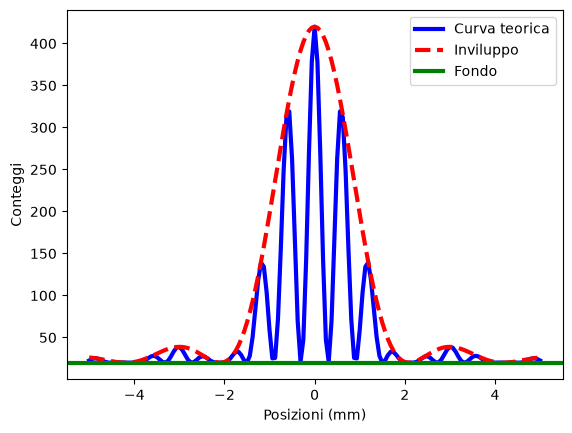

In [62]:
grafico, asse =plt.subplots()
asse.plot(x,Mu(x), "b-", lw=3, label="Curva teorica")
asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
asse.axhline(B, color="g", lw=3, label="Fondo")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.legend()

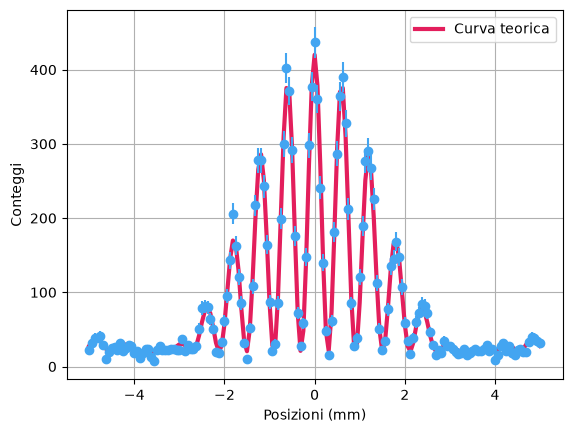

In [32]:
n=rng.poisson(Mu(x))
errori=[]
for ni in n:
    if ni==0:
        errori.append(1)
    else:
        errori.append(ni**0.5)
errors=np.array(errori)
grafico, asse =plt.subplots()
asse.plot(x,Mu(x), "-",color="#e31e5c", lw=3, label="Curva teorica")
#asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
#asse.axhline(B, color="g", lw=3, label="Fondo")
asse.errorbar(x,n,yerr=errors, fmt='o', color="#43a5f1")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.grid()
asse.legend()

In [ ]:
Nc=np.sum(n[abs(x) < 1.2])
mu_c=np.sum(Mu(x[abs(x) < 1.2]))
statistica=(Nc-mu_c)/(mu_c**0.5)
print(statistica)

0.8528032359317802


In [57]:
m=30000
def generatore(array):
    ni=rng.poisson(Mu(array))
    Nc_i=np.sum(ni[abs(array) < 1.2])
    return Nc_i

risultati_=[]
for i in range(m):
    risultati_.append(generatore(x))
risultati=np.array(risultati_)
media=risultati.mean()
dev_std=risultati.std(ddof=1)
dev_std_med=dev_std/(m**0.5)
scarto_rel=media-mu_c
rapporto_deviazioni=dev_std/(mu_c**0.5)

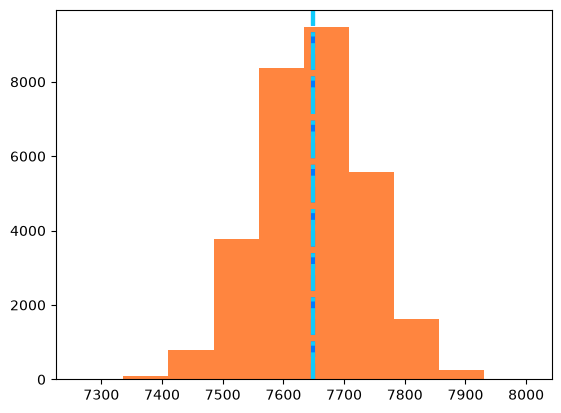

In [58]:
figura1, assi =plt.subplots()
assi.hist(risultati, color="#FF853F")
assi.axvline(media, color="#007BFF", lw=3, linestyle="--")
assi.axvline(mu_c, color="#10cBFb", lw=3, linestyle="-.")